In [1]:
# 그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression 
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler  # 정규화클래스
from sklearn.preprocessing import OneHotEncoder

In [2]:
df = pd.read_csv('data/MultipleLinearRegressionData.csv')
# 장소 뺀 컬럼
data = df.iloc[:, :-2].values
label = df.iloc[:, -1].values

In [3]:
df

,hour,absent,place,score
0,0.5,3,Home,10
1,1.2,4,Library,8
2,1.8,2,Cafe,14
3,2.4,0,Cafe,26
4,2.6,2,Home,22
5,3.2,0,Home,30
6,3.9,0,Library,42
7,4.4,0,Library,48
8,4.5,5,Home,38
9,5.0,1,Cafe,58


In [4]:
data[:3]

array([[0.5, 3. ],
       [1.2, 4. ],
       [1.8, 2. ]])

In [5]:
data.shape

(20, 2)

In [6]:
# 장소분리
place = df['place'].to_numpy().reshape(-1,1)
# 원핫인코딩 객체 생성
encoder = OneHotEncoder(sparse_output=False,drop='first')
# 원핫인코딩 적용
result = encoder.fit_transform(place)
result.shape

(20, 2)

In [7]:
# 숫자 데이터 + 원핫인코딩 결합
total_data = np.concatenate((data, result), axis=1)
total_data.shape

(20, 4)

In [8]:
# 1. 데이터 변환
data = np.array(total_data, dtype=float)
label = np.array(label, dtype=float)

In [9]:
# 2. 훈련데이터, 테스트데이터 분리
train_data, test_data, train_label, test_label = train_test_split(
    data, label, random_state=42, test_size=0.2
)

In [10]:
print('훈련데이터:', train_data.shape)
print('테스트데이터:', test_data.shape)

훈련데이터: (16, 4)
테스트데이터: (4, 4)


In [11]:
# 3. 다항 특성 자동 생성
poly = PolynomialFeatures(degree=2, include_bias=False)
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)

In [12]:
print('다항 특성 훈련 데이터:', train_poly.shape)
print('다항 특성 테스트 데이터:', test_poly.shape)

다항 특성 훈련 데이터: (16, 14)
다항 특성 테스트 데이터: (4, 14)


In [13]:
# 특성 이름 확인
print('생성된 특성:')
print(poly.get_feature_names_out())

생성된 특성:
['x0' 'x1' 'x2' 'x3' 'x0^2' 'x0 x1' 'x0 x2' 'x0 x3' 'x1^2' 'x1 x2' 'x1 x3'
 'x2^2' 'x2 x3' 'x3^2']


In [14]:
# 4. 표준화
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)

In [15]:
# 5. 릿지 회귀 - 규제 강도 탐색
train_score = []
test_score = []
alpha_list = [0.001, 0.01, 0.1, 1, 10, 100]
for alpha in alpha_list:
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled, train_label)
    train_score.append(ridge.score(train_scaled, train_label))
    test_score.append(ridge.score(test_scaled, test_label))

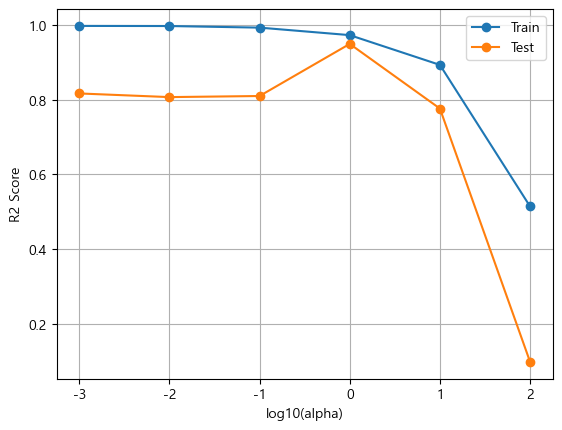

In [16]:
# 6. alpha별 성능 그래프
plt.plot(np.log10(alpha_list), train_score, marker='o')
plt.plot(np.log10(alpha_list), test_score, marker='o')
plt.xlabel('log10(alpha)')
plt.ylabel('R2 Score')
plt.legend(['Train', 'Test'])
plt.grid()
plt.show()

In [17]:
best_index = np.argmax(test_score)
best_alpha = alpha_list[best_index]
best_alpha

1

In [18]:
# 7. 최적 alpha 선정
best_index = np.argmax(test_score)   # 배열이나 리스트에서 가장 큰 값이 위치한 인덱스
best_alpha = alpha_list[best_index]
print('최적 alpha:', best_alpha)

최적 alpha: 1


In [19]:
# 8. 최적 alpha로 최종 모델 생성
ridge = Ridge(alpha=best_alpha)
ridge.fit(train_scaled, train_label)
print('\n[최종 모델 성능]')
print('훈련 정확도:', ridge.score(train_scaled, train_label))
print('테스트 정확도:', ridge.score(test_scaled, test_label))


[최종 모델 성능]
훈련 정확도: 0.9734652293004684
테스트 정확도: 0.9499195988807138


In [20]:
# 9. 예측 및 오차 확인
result = ridge.predict(test_scaled)

print('\n실제 정답:', test_label)
print('예측 결과:', result)


실제 정답: [10. 86. 58.  8.]
예측 결과: [ 1.18575003 85.04675574 68.00492186 14.30893426]


In [23]:
test_data[:1]

array([[0.5, 3. , 1. , 0. ]])

input() 입력받아 예측할때?

In [ ]:
# 입력받아 예측 할때
# 특성추가
in_data = poly.transform([[0.5, 3. , 1. , 0. ]])
in_data
# 정규화
in_scaled = ss.transform(in_data)
in_scaled

# 예측값
result_data = ridge.predict(in_scaled)
result_data
# 

array([1.18575003])

In [22]:
test_scaled[:1]

array([[-2.17322845,  1.29986737,  2.081666  , -0.77459667, -1.24426737,
        -0.70167888, -0.10391295, -0.7140186 ,  0.92493962,  2.01261084,
        -0.40689423,  2.081666  ,  0.        , -0.77459667]])

In [21]:
mae = mean_absolute_error(test_label, result)
print('평균 절대 오차(MAE):', mae)

평균 절대 오차(MAE): 6.520337587651122
